# UTS Graf Sains Data 

### Menyiapkan Driver Neo4j

Library `neo4j` digunakan agar Python bisa berkomunikasi dengan database Neo4j. Cell ini memasang driver yang dibutuhkan jika belum tersedia di environment notebook.

In [1]:
%pip install neo4j

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


### Mengimpor Library

Bagian ini memanggil library yang dipakai selama pengerjaan. `pandas` untuk mengolah data, `numpy` untuk perhitungan, `Path` untuk mengatur lokasi file, `GraphDatabase` untuk koneksi Neo4j, `getpass` untuk memasukkan password, dan `tqdm` untuk menampilkan progres.

In [73]:
from pathlib import Path
import pandas as pd
import numpy as np
from neo4j import GraphDatabase
from getpass import getpass
from tqdm.auto import tqdm

## Pengerjaan Soal 2.1 Wrangling dan EDA (Maks. skor: 45)

### Memeriksa Lokasi Dataset

Cell ini menetapkan lokasi `events.csv` lalu memeriksa apakah file tersedia. Pemeriksaan dilakukan di awal supaya proses berhenti dengan pesan yang jelas jika lokasi dataset belum sesuai.

In [74]:
DATA_PATH = Path("data/raw/events.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset tidak ditemukan: {DATA_PATH.resolve()}"
    )

### Membaca Dataset

Dataset dibaca menjadi DataFrame bernama `df`. Informasi ukuran data, nama kolom, dan beberapa baris awal ditampilkan untuk memastikan data berhasil dibaca dan bentuk kolomnya sesuai.

In [75]:
df = pd.read_csv(DATA_PATH)

print("Dataset berhasil dibaca!")
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

display(df.head())

Dataset berhasil dibaca!
Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


### Mengubah Timestamp ke Format Waktu

Kolom `timestamp` berisi waktu dalam format Unix milidetik. Nilainya diubah menjadi tanggal dan waktu UTC agar bisa digunakan untuk memisahkan data berdasarkan periode. Cell ini juga menampilkan rentang tanggal serta jumlah timestamp yang gagal dikonversi.

In [76]:
df["datetime_utc"] = pd.to_datetime(
    df["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

print("Tanggal paling awal:", df["datetime_utc"].min())
print("Tanggal paling akhir:", df["datetime_utc"].max())

print(
    "Timestamp gagal dikonversi:",
    df["datetime_utc"].isna().sum()
)

Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00
Timestamp gagal dikonversi: 0


## Bagian 1 : Wrangling dan Exploratory Data Analysis (EDA)

Pada bagian ini, data interaksi diperiksa dan disiapkan sebelum masuk ke pembentukan graf. Tahapannya mencakup penentuan periode training dan testing, pemisahan data, pemeriksaan hasil filtering, ringkasan interaksi, serta penyimpanan data ke file terpisah.

### Menentukan Periode Training dan Testing

Dua rentang waktu ditetapkan untuk membedakan data yang digunakan membangun model dan data yang digunakan menguji hasilnya. P1 mencakup 5–7 Juli 2015, sedangkan P2 mencakup 16–31 Juli 2015. Batas akhir dibuat eksklusif agar seluruh waktu pada tanggal terakhir ikut terambil.

In [77]:

P1_START = pd.Timestamp("2015-07-05 00:00:00", tz="UTC")
P1_END   = pd.Timestamp("2015-07-08 00:00:00", tz="UTC")
P2_START = pd.Timestamp("2015-07-16 00:00:00", tz="UTC")
P2_END   = pd.Timestamp("2015-08-01 00:00:00", tz="UTC")

### Memisahkan Data Berdasarkan Periode

Data disaring berdasarkan kolom waktu yang sudah dikonversi. Interaksi pada P1 disimpan ke `train_df`, sedangkan interaksi pada P2 disimpan ke `test_df`. Data asli tetap dipertahankan karena proses menggunakan `.copy()`.

In [78]:

train_df = df.loc[
    (df["datetime_utc"] >= P1_START) &
    (df["datetime_utc"] < P1_END)
].copy()

test_df = df.loc[
    (df["datetime_utc"] >= P2_START) &
    (df["datetime_utc"] < P2_END)
].copy()

### Memvalidasi Hasil Filtering

Cell ini memastikan data training dan testing tidak kosong serta periode keduanya tidak bertumpang tindih. Jumlah data dan rentang waktu masing-masing periode ditampilkan untuk membantu pemeriksaan hasil pemisahan.

In [79]:

assert len(train_df) > 0, "Data training kosong!"
assert len(test_df) > 0, "Data testing kosong!"

assert train_df["datetime_utc"].max() < test_df["datetime_utc"].min(), (
    "Periode training dan testing bertumpang tindih!"
)

print("FILTERING BERHASIL")
print("-" * 45)
print("Jumlah data training:", len(train_df))
print("Jumlah data testing :", len(test_df))

print("\nRentang waktu training:")
print(train_df["datetime_utc"].min(), "sampai", train_df["datetime_utc"].max())

print("\nRentang waktu testing:")
print(test_df["datetime_utc"].min(), "sampai", test_df["datetime_utc"].max())

FILTERING BERHASIL
---------------------------------------------
Jumlah data training: 62491
Jumlah data testing : 364206

Rentang waktu training:
2015-07-05 00:00:14.030000+00:00 sampai 2015-07-07 23:59:56.642000+00:00

Rentang waktu testing:
2015-07-16 00:00:05.597000+00:00 sampai 2015-07-31 23:59:58.354000+00:00


### Ringkasan Data Training dan Testing

Fungsi `ringkasan_fold()` merangkum jumlah interaksi, jumlah pengguna unik, jumlah item unik, dan distribusi jenis interaksi. Ringkasan ini membantu melihat perbedaan isi data P1 dan P2 sebelum masuk ke proses graf.

In [80]:
def ringkasan_fold(nama, data):
    print(f"\n{'=' * 45}")
    print(nama)
    print(f"{'=' * 45}")

    print("Jumlah interaksi :", len(data))
    print("Jumlah User unik :", data["visitorid"].nunique())
    print("Jumlah Item unik :", data["itemid"].nunique())

    print("\nDistribusi jenis interaksi:")
    display(
        data["event"]
        .value_counts()
        .rename_axis("Jenis Interaksi")
        .reset_index(name="Jumlah")
    )
ringkasan_fold("FOLD TRAINING (P1)", train_df)
ringkasan_fold("FOLD TESTING (P2)", test_df)


FOLD TRAINING (P1)
Jumlah interaksi : 62491
Jumlah User unik : 34436
Jumlah Item unik : 29766

Distribusi jenis interaksi:


,Jenis Interaksi,Jumlah
0,view,60224
1,addtocart,1701
2,transaction,566



FOLD TESTING (P2)
Jumlah interaksi : 364206
Jumlah User unik : 199899
Jumlah Item unik : 88699

Distribusi jenis interaksi:


,Jenis Interaksi,Jumlah
0,view,351830
1,addtocart,9263
2,transaction,3113


### Menyimpan Data Hasil Filtering

Data P1 dan P2 disimpan ke folder `data/processed` dalam dua file CSV terpisah. File ini dipakai kembali pada tahap berikutnya, termasuk saat data training dimasukkan ke Neo4j.

In [81]:

OUTPUT_DIR = Path("data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

columns_to_save = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

train_path = OUTPUT_DIR / "events_P1_train.csv"
train_df[columns_to_save].to_csv(
    train_path,
    index=False
)

test_path = OUTPUT_DIR / "events_P2_test.csv"
test_df[columns_to_save].to_csv(
    test_path,
    index=False
)
print("CSV berhasil disimpan:")
print("Training:", train_path.resolve())
print("Testing :", test_path.resolve())

CSV berhasil disimpan:
Training: C:\Users\user\gsd_uts\data\processed\events_P1_train.csv
Testing : C:\Users\user\gsd_uts\data\processed\events_P2_test.csv


### Mengatur Koneksi ke Neo4j

Alamat database dan nama pengguna ditentukan, lalu password diminta secara tersembunyi. Setelah driver dibuat, `verify_connectivity()` memeriksa apakah Python berhasil tersambung ke Neo4j.

In [83]:
URI = "bolt://127.0.0.1:7687"
USERNAME = "neo4j"
PASSWORD = getpass("Masukkan password Neo4j: ")

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()
print("Koneksi Neo4j berhasil!")

Koneksi Neo4j berhasil!


### Menguji Session Neo4j

Cell ini membuka session ke database `neo4j` dan menjalankan query sederhana untuk memastikan session bisa dipakai. Session ditutup kembali pada bagian `finally`, termasuk jika terjadi kesalahan saat query dijalankan.

In [84]:
session = driver.session(database="neo4j")
try:
    result = session.run(
        "RETURN 'Session Neo4j berhasil dibuat' AS status"
    ).single()

    print(result["status"])

finally:
    session.close()

Session Neo4j berhasil dibuat


### Memeriksa Kondisi Awal Database

Jumlah node dan relationship yang sudah ada di database dihitung sebelum proses impor. Pemeriksaan ini membantu memastikan kondisi database diketahui terlebih dahulu dan mencegah data lama tercampur tanpa disadari.

In [85]:
with driver.session(database="neo4j") as session:

    node_result = session.run(
        "MATCH (n) RETURN count(n) AS jumlah_node"
    ).single()

    rel_result = session.run(
        "MATCH ()-[r]->() "
        "RETURN count(r) AS jumlah_relationship"
    ).single()

print("Jumlah node:", node_result["jumlah_node"])
print(
    "Jumlah relationship:",
    rel_result["jumlah_relationship"]
)

Jumlah node: 0
Jumlah relationship: 0


### Membuat Constraint ID

Fungsi ini membuat constraint agar `visitorId` pada node Visitor dan `itemId` pada node Item bersifat unik. Dengan begitu, Neo4j dapat menjaga agar identitas pengguna dan item tidak dibuat berulang dengan ID yang sama.

In [86]:
def create_constraints(session):
    """
    Membuat constraint agar ID Visitor dan Item unik.
    """

    session.run("""
        CREATE CONSTRAINT visitor_id_unique IF NOT EXISTS
        FOR (v:Visitor)
        REQUIRE v.visitorId IS UNIQUE
    """).consume()

    session.run("""
        CREATE CONSTRAINT item_id_unique IF NOT EXISTS
        FOR (i:Item)
        REQUIRE i.itemId IS UNIQUE
    """).consume()

    print("Constraint Visitor dan Item berhasil dibuat.")

### Menyiapkan Fungsi Impor Batch ke Neo4j

Fungsi `import_batch()` mengubah baris interaksi menjadi node Visitor, node Item, dan relationship sesuai jenis event. Event `view`, `addtocart`, dan `transaction` masing-masing direpresentasikan sebagai `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`. Fungsi ini disiapkan terlebih dahulu untuk dipanggil saat impor batch berlangsung.

In [87]:
def import_batch(tx, batch):

    cypher_query = """
    UNWIND $batch AS row

    MERGE (v:Visitor {visitorId: row.visitorid})
    MERGE (i:Item {itemId: row.itemid})

    WITH v, i, row

    CALL {
        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'view'

        CREATE (v)-[:VIEWED {
            timestamp: row.timestamp
        }]->(i)

        RETURN 1 AS imported

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'addtocart'

        CREATE (v)-[:ADDED_TO_CART {
            timestamp: row.timestamp
        }]->(i)

        RETURN 1 AS imported

        UNION ALL

        WITH v, i, row
        WITH v, i, row
        WHERE row.event = 'transaction'

        CREATE (v)-[:BOUGHT {
            timestamp: row.timestamp,
            transactionId: row.transactionid
        }]->(i)

        RETURN 1 AS imported
    }

    RETURN count(imported) AS imported_rows
    """

    result = tx.run(
        cypher_query,
        batch=batch
    )

    return result.single()["imported_rows"]

### Menyiapkan File dan Ukuran Batch

Cell ini memeriksa keberadaan file training, menentukan ukuran setiap batch, menghitung jumlah baris data, dan memperkirakan jumlah batch yang perlu diproses. Pembagian batch membantu impor data dalam jumlah besar dilakukan secara bertahap.

In [88]:
csv_file_path = Path(
    "data/processed/events_P1_train.csv"
)

if not csv_file_path.exists():
    raise FileNotFoundError(
        f"File tidak ditemukan: {csv_file_path.resolve()}"
    )

batch_size = 5000

with open(
    csv_file_path,
    "r",
    encoding="utf-8-sig",
    newline=""
) as f:
    total_rows = sum(1 for _ in f) - 1

if total_rows <= 0:
    raise ValueError("File training kosong!")

total_chunks = (
    total_rows + batch_size - 1
) // batch_size

print(f"Membaca file data dari: {csv_file_path.resolve()}")
print(f"Total baris: {total_rows}")
print(f"Batch size: {batch_size}")
print(f"Total batch: {total_chunks}")

Membaca file data dari: C:\Users\user\gsd_uts\data\processed\events_P1_train.csv
Total baris: 62491
Batch size: 5000
Total batch: 13


### Memastikan Database Siap untuk Impor

Sebelum mengimpor, cell ini memeriksa jumlah node dan relationship yang ada. Proses dihentikan jika database tidak kosong agar relationship tidak terduplikasi, kemudian constraint untuk ID Visitor dan Item dibuat.

In [89]:
with driver.session(database="neo4j") as session:

    existing_nodes = session.run("""
        MATCH (n)
        RETURN count(n) AS total
    """).single()["total"]

    existing_relationships = session.run("""
        MATCH ()-[r]->()
        RETURN count(r) AS total
    """).single()["total"]

    print("Jumlah node:", existing_nodes)
    print("Jumlah relationship:", existing_relationships)

Jumlah node: 0
Jumlah relationship: 0


### Mengimpor Data Training secara Bertahap

File training dibaca per batch, nilai `transactionid` yang kosong dibersihkan, lalu setiap batch dikirim ke Neo4j menggunakan fungsi impor yang telah disiapkan. Pada akhir proses, jumlah baris yang berhasil diimpor dibandingkan dengan jumlah baris di CSV.

In [90]:

print("Memulai proses impor data ke Neo4j...")

try:
    imported_rows = 0

    with driver.session(database="neo4j") as session:

        chunks = pd.read_csv(
            csv_file_path,
            chunksize=batch_size,
            dtype={"transactionid": "string"}
        )

        for chunk in tqdm(
            chunks,
            total=total_chunks,
            desc="Mengimpor Batch Data"
        ):

            chunk["transactionid"] = (
                chunk["transactionid"]
                .fillna("")
                .astype(str)
            )

            records = chunk.to_dict(orient="records")

            batch_imported = session.execute_write(
                import_batch,
                records
            )

            imported_rows += batch_imported

    print("\nProses impor selesai.")
    print("Jumlah baris yang diproses:", imported_rows)

    assert imported_rows == total_rows, (
        f"Jumlah record tidak sesuai: "
        f"{imported_rows} dari {total_rows}"
    )

except Exception as e:
    print("Proses impor gagal:", e)
    raise

Memulai proses impor data ke Neo4j...


Mengimpor Batch Data:   0%|          | 0/13 [00:00<?, ?it/s]

Received notification from DBMS server: <GqlStatusObject gql_status='01N00', status_description='warn: feature deprecated. CALL subquery without a variable scope clause is deprecated. Use CALL (v, i, row) { ... }', position=<SummaryInputPosition line=9, column=5, offset=141>, raw_classification='DEPRECATION', classification=<NotificationClassification.DEPRECATION: 'DEPRECATION'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'DEPRECATION', '_severity': 'WARNING', '_position': {'offset': 141, 'line': 9, 'column': 5}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "\n    UNWIND $batch AS row\n\n    MERGE (v:Visitor {visitorId: row.visitorid})\n    MERGE (i:Item {itemId: row.itemid})\n\n    WITH v, i, row\n\n    CALL {\n        WITH v, i, row\n        WITH v, i, row\n        WHERE row.event = 'view'\n\n        CREATE (v)-[:VIEWED {\n            timestamp: row.timestamp\n        }]->(i)\n\n     


Proses impor selesai.
Jumlah baris yang diproses: 62491


## Bagian 2 : Memeriksa Hasil Impor pada Neo4j

Setelah data training dimasukkan ke database, graf perlu diperiksa sebelum dipakai untuk analisis berikutnya. Tahap ini melihat apakah node dan hubungan sudah terbentuk, sekaligus menjadi awal pemeriksaan struktur graf.

### Metode: Memeriksa Komposisi Graf Neo4j

Query Cypher menghitung jumlah node berdasarkan label dan jumlah relationship berdasarkan jenisnya. Hasil ini menunjukkan komposisi graf yang terbentuk dari interaksi training, yaitu node Visitor dan Item serta hubungan `VIEWED`, `ADDED_TO_CART`, dan `BOUGHT`.

In [91]:
with driver.session(database="neo4j") as session:

    node_stats = session.run("""
        MATCH (n)
        UNWIND labels(n) AS label
        RETURN label, count(*) AS jumlah
        ORDER BY label
    """).data()

    relationship_stats = session.run("""
        MATCH ()-[r]->()
        RETURN type(r) AS jenis_relationship,
               count(r) AS jumlah
        ORDER BY jenis_relationship
    """).data()

    total_nodes = session.run("""
        MATCH (n)
        RETURN count(n) AS total
    """).single()["total"]

    total_relationships = session.run("""
        MATCH ()-[r]->()
        RETURN count(r) AS total
    """).single()["total"]

print("Total node:", total_nodes)
print("Total relationship:", total_relationships)

print("\nKomposisi node:")
display(pd.DataFrame(node_stats))

print("\nKomposisi relationship:")
display(pd.DataFrame(relationship_stats))

Total node: 64202
Total relationship: 62491

Komposisi node:


,label,jumlah
0,Item,29766
1,Visitor,34436



Komposisi relationship:


,jenis_relationship,jumlah
0,ADDED_TO_CART,1701
1,BOUGHT,566
2,VIEWED,60224


### Mengambil Hubungan User–Item dari Neo4j

Data relationship dari Visitor ke Item diambil melalui query Cypher. Hasilnya disusun menjadi DataFrame berisi pasangan `visitorid` dan `itemid` yang unik. Pasangan ini menjadi dasar untuk membentuk matriks VSM.

In [92]:

with driver.session(database="neo4j") as session:

    user_item_query = """
    MATCH (v:Visitor)-[r]->(i:Item)
    RETURN DISTINCT
        v.visitorId AS visitorid,
        i.itemId AS itemid
    """

    user_item_records = session.run(
        user_item_query
    ).data()

user_item_df = pd.DataFrame(user_item_records)

if user_item_df.empty:
    raise ValueError(
        "Tidak ditemukan hubungan Visitor–Item pada graf."
    )

print("Jumlah pasangan User–Item unik:", len(user_item_df))

print("\nContoh hubungan User–Item:")
display(user_item_df.head())

Jumlah pasangan User–Item unik: 50113

Contoh hubungan User–Item:


,visitorid,itemid
0,907974,344338
1,1035462,344338
2,516945,215795
3,655238,215795
4,949981,31019


### Membentuk Matriks VSM User

Setiap baris mewakili User dan setiap kolom mewakili Item. Nilai 1 menunjukkan bahwa User pernah berinteraksi dengan Item tersebut. Matriks dibuat dalam format sparse CSR supaya lebih hemat memori karena kebanyakan pasangan User–Item tidak memiliki interaksi.

In [93]:

import numpy as np
from scipy.sparse import csr_matrix

user_ids = sorted(user_item_df["visitorid"].unique())
item_ids = sorted(user_item_df["itemid"].unique())

user_to_idx = {
    user_id: idx
    for idx, user_id in enumerate(user_ids)
}

item_to_idx = {
    item_id: idx
    for idx, item_id in enumerate(item_ids)
}

rows = user_item_df["visitorid"].map(
    user_to_idx
).to_numpy()

cols = user_item_df["itemid"].map(
    item_to_idx
).to_numpy()

values = np.ones(
    len(user_item_df),
    dtype=np.uint8
)

user_item_matrix = csr_matrix(
    (values, (rows, cols)),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.uint8
)

print("Matriks VSM User berhasil dibuat.")

Matriks VSM User berhasil dibuat.


### Memeriksa Karakteristik VSM User

Cell ini menghitung ukuran matriks, jumlah nilai yang terisi, density, sparsity, serta ringkasan jumlah item per pengguna. Informasi tersebut memberi gambaran seberapa padat atau jarang interaksi pada matriks User–Item.

In [94]:

n_users, n_items = user_item_matrix.shape

n_nonzero = user_item_matrix.nnz
total_positions = n_users * n_items

density = n_nonzero / total_positions
sparsity = 1 - density

items_per_user = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

print("=" * 55)
print("KARAKTERISTIK VECTOR SPACE MODELLING - USER")
print("=" * 55)

print("Jumlah User               :", n_users)
print("Jumlah fitur Item         :", n_items)
print("Dimensi matriks           :", user_item_matrix.ndim)
print("Shape matriks             :", user_item_matrix.shape)
print("Jumlah nilai nonzero      :", n_nonzero)
print("Jumlah seluruh posisi     :", total_positions)
print("Density                   :", f"{density:.8%}")
print("Sparsity                  :", f"{sparsity:.8%}")
print("Rata-rata Item per User   :", round(items_per_user.mean(), 3))
print("Median Item per User      :", np.median(items_per_user))
print("Item minimum per User     :", items_per_user.min())
print("Item maksimum per User    :", items_per_user.max())
print("Format matriks            :", type(user_item_matrix).__name__)

KARAKTERISTIK VECTOR SPACE MODELLING - USER
Jumlah User               : 34436
Jumlah fitur Item         : 29766
Dimensi matriks           : 2
Shape matriks             : (34436, 29766)
Jumlah nilai nonzero      : 50113
Jumlah seluruh posisi     : 1025021976
Density                   : 0.00488897%
Sparsity                  : 99.99511103%
Rata-rata Item per User   : 1.455
Median Item per User      : 1.0
Item minimum per User     : 1
Item maksimum per User    : 394
Format matriks            : csr_matrix


### Membentuk User Projection

User Projection menghubungkan dua pengguna jika keduanya pernah berinteraksi dengan item yang sama. Cell ini memilih sebagian pengguna sebagai sampel, menghitung tumpang tindih item, dan membangun graf pengguna yang akan divisualisasikan.

In [95]:

import networkx as nx
import matplotlib.pyplot as plt

candidate_n = min(300, len(user_ids))
plot_n = min(100, candidate_n)

user_activity = np.asarray(
    user_item_matrix.sum(axis=1)
).ravel()

candidate_positions = np.argsort(
    user_activity
)[-candidate_n:]

candidate_matrix = user_item_matrix[
    candidate_positions
].astype(np.int32)

candidate_overlap = (
    candidate_matrix @ candidate_matrix.T
)

candidate_overlap.setdiag(0)
candidate_overlap.eliminate_zeros()

candidate_neighbors = np.asarray(
    (candidate_overlap > 0).sum(axis=1)
).ravel()

chosen_local_positions = np.argsort(
    candidate_neighbors
)[-plot_n:]

selected_positions = candidate_positions[
    chosen_local_positions
]

selected_user_ids = [
    user_ids[idx] for idx in selected_positions
]

sample_matrix = user_item_matrix[
    selected_positions
].astype(np.int32)

overlap_matrix = sample_matrix @ sample_matrix.T

overlap_matrix.setdiag(0)
overlap_matrix.eliminate_zeros()

G_user = nx.Graph()

G_user.add_nodes_from(selected_user_ids)

overlap_coo = overlap_matrix.tocoo()

for i, j, weight in zip(
    overlap_coo.row,
    overlap_coo.col,
    overlap_coo.data
):
    if i < j and weight > 0:
        G_user.add_edge(
            selected_user_ids[i],
            selected_user_ids[j],
            weight=int(weight)
        )

print("Jumlah node pada graf visualisasi:", G_user.number_of_nodes())
print("Jumlah edge pada graf visualisasi:", G_user.number_of_edges())

Jumlah node pada graf visualisasi: 100
Jumlah edge pada graf visualisasi: 533


### Memvisualisasikan User Projection

Graf pengguna yang telah dibentuk ditampilkan menggunakan NetworkX. Titik menunjukkan pengguna, sedangkan garis menunjukkan hubungan antar-pengguna berdasarkan item yang sama. Tata letak digunakan untuk membantu melihat pola hubungan dalam sampel graf.

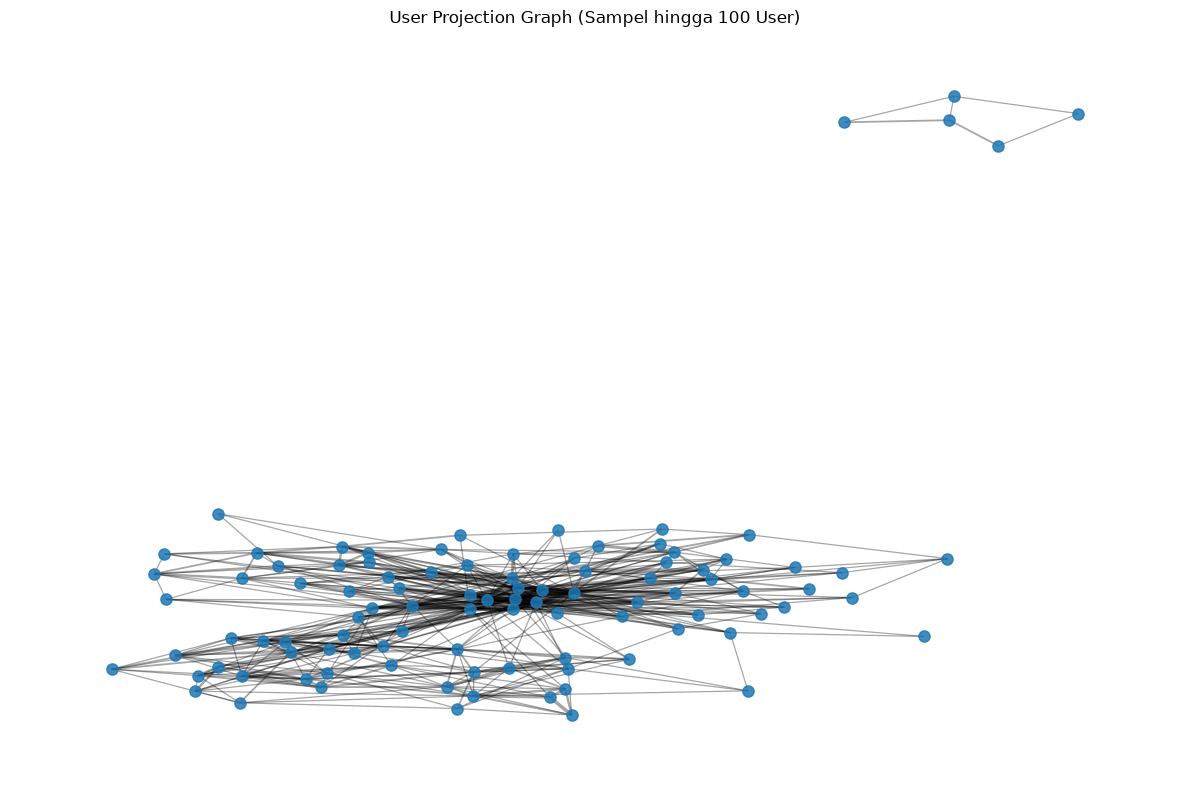

In [96]:

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(
    G_user,
    seed=42
)

nx.draw_networkx_nodes(
    G_user,
    pos,
    node_size=65,
    alpha=0.85
)

if G_user.number_of_edges() > 0:
    edge_widths = [
        0.5 + 0.4 * min(
            G_user[u][v]["weight"], 5
        )
        for u, v in G_user.edges()
    ]

    nx.draw_networkx_edges(
        G_user,
        pos,
        width=edge_widths,
        alpha=0.35
    )

plt.title(
    "User Projection Graph (Sampel hingga 100 User)"
)
plt.axis("off")
plt.tight_layout()
plt.show()

### Membentuk Matriks VSM Item

Matriks User–Item ditransposisikan sehingga setiap baris sekarang mewakili Item dan setiap kolom mewakili User. Dengan cara ini, riwayat pengguna yang berinteraksi dengan suatu item dapat dibandingkan untuk analisis berbasis Item.

In [97]:

from scipy.sparse import csr_matrix

item_user_matrix = user_item_matrix.T.tocsr()

print("Matriks VSM Item berhasil dibuat.")
print("Shape matriks:", item_user_matrix.shape)
print("Jumlah dimensi:", item_user_matrix.ndim)
print("Jumlah nilai nonzero:", item_user_matrix.nnz)
print("Format matriks:", type(item_user_matrix).__name__)

Matriks VSM Item berhasil dibuat.
Shape matriks: (29766, 34436)
Jumlah dimensi: 2
Jumlah nilai nonzero: 50113
Format matriks: csr_matrix


### Memeriksa Karakteristik VSM Item

Cell ini menghitung dimensi, jumlah nilai yang terisi, density, sparsity, serta jumlah pengguna yang berinteraksi dengan setiap item. Ringkasan ini membantu memahami seberapa banyak item yang memiliki pengguna pendukung.

In [98]:

n_items_vsm, n_users_vsm = item_user_matrix.shape

n_nonzero_item = item_user_matrix.nnz
total_positions_item = n_items_vsm * n_users_vsm

density_item = n_nonzero_item / total_positions_item
sparsity_item = 1 - density_item

users_per_item = np.asarray(
    item_user_matrix.sum(axis=1)
).ravel()

print("=" * 55)
print("KARAKTERISTIK VECTOR SPACE MODELLING - ITEM")
print("=" * 55)

print("Jumlah Item             :", n_items_vsm)
print("Jumlah fitur User       :", n_users_vsm)
print("Dimensi matriks         :", item_user_matrix.ndim)
print("Shape matriks           :", item_user_matrix.shape)
print("Jumlah nilai nonzero    :", n_nonzero_item)
print("Jumlah seluruh posisi   :", total_positions_item)
print("Density                 :", f"{density_item:.8%}")
print("Sparsity                :", f"{sparsity_item:.8%}")
print("Rata-rata User per Item :", round(users_per_item.mean(), 3))
print("Median User per Item    :", np.median(users_per_item))
print("User minimum per Item   :", users_per_item.min())
print("User maksimum per Item  :", users_per_item.max())
print("Format matriks          :", type(item_user_matrix).__name__)

KARAKTERISTIK VECTOR SPACE MODELLING - ITEM
Jumlah Item             : 29766
Jumlah fitur User       : 34436
Dimensi matriks         : 2
Shape matriks           : (29766, 34436)
Jumlah nilai nonzero    : 50113
Jumlah seluruh posisi   : 1025021976
Density                 : 0.00488897%
Sparsity                : 99.99511103%
Rata-rata User per Item : 1.684
Median User per Item    : 1.0
User minimum per Item   : 1
User maksimum per Item  : 70
Format matriks          : csr_matrix


### Membentuk Item Projection

Item Projection menghubungkan dua item jika keduanya pernah diinteraksikan oleh pengguna yang sama. Cell ini memilih sampel item, menghitung jumlah pengguna yang sama untuk pasangan item, kemudian membentuk graf item untuk dianalisis lebih lanjut.

In [99]:

import networkx as nx
import matplotlib.pyplot as plt

candidate_n = min(300, len(item_ids))

plot_n = min(100, candidate_n)

candidate_positions = np.argsort(
    users_per_item
)[-candidate_n:]

candidate_matrix = item_user_matrix[
    candidate_positions
].astype(np.int32)

candidate_overlap = (
    candidate_matrix @ candidate_matrix.T
)

candidate_overlap.setdiag(0)
candidate_overlap.eliminate_zeros()

candidate_neighbors = np.asarray(
    (candidate_overlap > 0).sum(axis=1)
).ravel()

chosen_local_positions = np.argsort(
    candidate_neighbors
)[-plot_n:]

selected_item_positions = candidate_positions[
    chosen_local_positions
]

selected_item_ids = [
    item_ids[idx]
    for idx in selected_item_positions
]

sample_item_matrix = item_user_matrix[
    selected_item_positions
].astype(np.int32)

overlap_matrix_item = (
    sample_item_matrix @ sample_item_matrix.T
)

overlap_matrix_item.setdiag(0)
overlap_matrix_item.eliminate_zeros()

G_item = nx.Graph()
G_item.add_nodes_from(selected_item_ids)

overlap_coo_item = overlap_matrix_item.tocoo()

for i, j, weight in zip(
    overlap_coo_item.row,
    overlap_coo_item.col,
    overlap_coo_item.data
):
    if i < j and weight > 0:
        G_item.add_edge(
            selected_item_ids[i],
            selected_item_ids[j],
            weight=int(weight)
        )

print("Jumlah node pada graf Item:", G_item.number_of_nodes())
print("Jumlah edge pada graf Item:", G_item.number_of_edges())
print("Density graf:", round(nx.density(G_item), 4))
print(
    "Jumlah connected components:",
    nx.number_connected_components(G_item)
)

Jumlah node pada graf Item: 100
Jumlah edge pada graf Item: 829
Density graf: 0.1675
Jumlah connected components: 1


### Memvisualisasikan Item Projection

Graf item ditampilkan dengan warna untuk membedakan connected components dan ukuran node yang berkaitan dengan degree. Visualisasi ini membantu melihat kelompok item yang saling terhubung melalui pengguna yang sama.

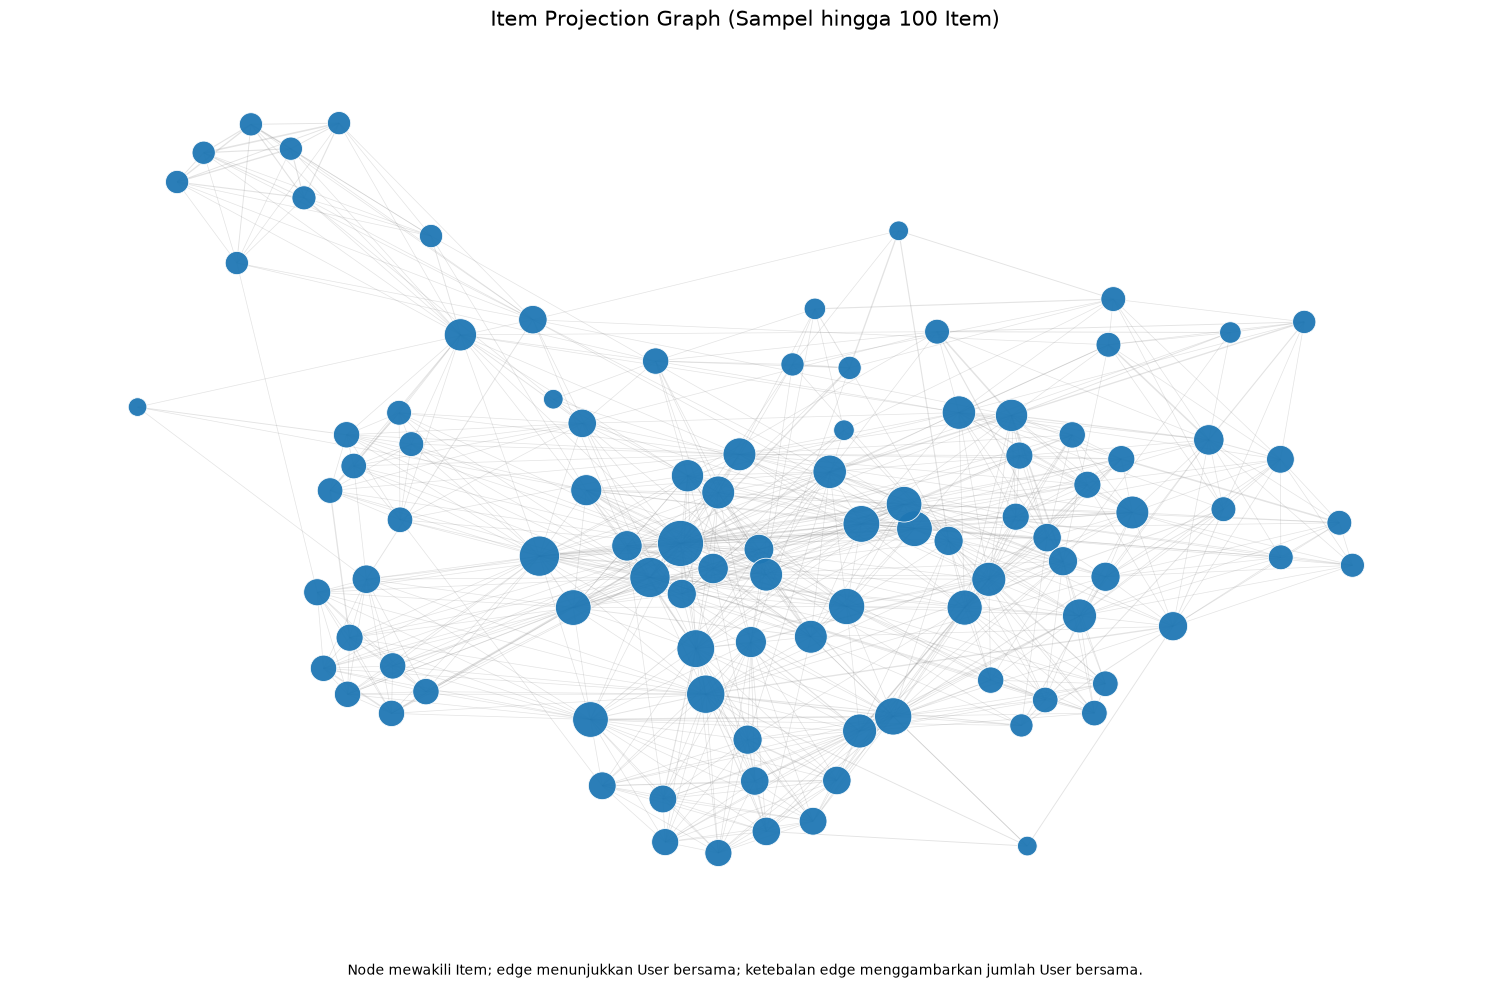

Jumlah connected components: 1
Ukuran komponen terbesar: 100


In [100]:

components_item = sorted(
    nx.connected_components(G_item),
    key=len,
    reverse=True
)

component_id_item = {
    node: i
    for i, component in enumerate(components_item)
    for node in component
}

component_colors_item = {
    i: plt.cm.tab20(i % 20)
    for i in range(len(components_item))
}

node_colors_item = [
    component_colors_item[component_id_item[node]]
    for node in G_item.nodes()
]

degree_item = dict(G_item.degree())

node_sizes_item = [
    100 + 20 * degree_item[node]
    for node in G_item.nodes()
]

pos_item = nx.spring_layout(
    G_item,
    seed=42,
    iterations=300,
    weight=None
)

plt.figure(figsize=(15, 10))

if G_item.number_of_edges() > 0:
    edge_widths_item = [
        0.35 + 0.15 * min(
            G_item[u][v]["weight"], 5
        )
        for u, v in G_item.edges()
    ]

    nx.draw_networkx_edges(
        G_item,
        pos_item,
        width=edge_widths_item,
        edge_color="gray",
        alpha=0.22
    )

nx.draw_networkx_nodes(
    G_item,
    pos_item,
    node_size=node_sizes_item,
    node_color=node_colors_item,
    edgecolors="white",
    linewidths=0.6,
    alpha=0.95
)

plt.title(
    "Item Projection Graph (Sampel hingga 100 Item)",
    fontsize=15,
    pad=15
)

plt.figtext(
    0.5,
    0.02,
    "Node mewakili Item; edge menunjukkan User bersama; "
    "ketebalan edge menggambarkan jumlah User bersama.",
    ha="center",
    fontsize=10
)

plt.axis("off")
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

print("Jumlah connected components:", len(components_item))
print(
    "Ukuran komponen terbesar:",
    len(components_item[0]) if components_item else 0
)

### Membandingkan User Projection dan Item Projection

Cell ini menghitung ukuran dasar matriks User–Item dan memperkirakan jumlah pasangan yang bisa terbentuk pada masing-masing proyeksi. Hasilnya digunakan untuk membandingkan potensi ukuran graf dan beban komputasi antara proyeksi pengguna dan proyeksi item.

In [101]:

import time
import numpy as np
import pandas as pd

X = user_item_matrix.astype(np.int32).tocsr()

n_users, n_items = X.shape

print("Shape VSM User-Item:", X.shape)

items_per_user_full = np.asarray(
    X.sum(axis=1)
).ravel().astype(np.int64)

users_per_item_full = np.asarray(
    X.sum(axis=0)
).ravel().astype(np.int64)

possible_user_pairs = n_users * (n_users - 1) // 2
possible_item_pairs = n_items * (n_items - 1) // 2

user_pair_contributions = int(
    np.sum(
        users_per_item_full
        * (users_per_item_full - 1) // 2,
        dtype=np.int64
    )
)

item_pair_contributions = int(
    np.sum(
        items_per_user_full
        * (items_per_user_full - 1) // 2,
        dtype=np.int64
    )
)

print("\nEstimasi pasangan sebelum duplikasi dihilangkan:")
print("User projection:", user_pair_contributions)
print("Item projection:", item_pair_contributions)

start = time.perf_counter()

A_user_proj = (X @ X.T).tocsr()

A_user_proj.setdiag(0)
A_user_proj.eliminate_zeros()

user_projection_time = time.perf_counter() - start

user_edges = A_user_proj.nnz // 2

user_density = (
    user_edges / possible_user_pairs
    if possible_user_pairs > 0 else 0
)

start = time.perf_counter()

A_item_proj = (X.T @ X).tocsr()

A_item_proj.setdiag(0)
A_item_proj.eliminate_zeros()

item_projection_time = time.perf_counter() - start

item_edges = A_item_proj.nnz // 2

item_density = (
    item_edges / possible_item_pairs
    if possible_item_pairs > 0 else 0
)

comparison_df = pd.DataFrame([
    {
        "Proyeksi": "User Projection",
        "Jumlah node": n_users,
        "Kemungkinan pasangan": possible_user_pairs,
        "Kontribusi pasangan": user_pair_contributions,
        "Edge unik": user_edges,
        "Density": user_density,
        "Waktu (detik)": user_projection_time
    },
    {
        "Proyeksi": "Item Projection",
        "Jumlah node": n_items,
        "Kemungkinan pasangan": possible_item_pairs,
        "Kontribusi pasangan": item_pair_contributions,
        "Edge unik": item_edges,
        "Density": item_density,
        "Waktu (detik)": item_projection_time
    }
])

print("\n=== PERBANDINGAN PROYEKSI PENUH ===")
display(comparison_df.round(6))

Shape VSM User-Item: (34436, 29766)

Estimasi pasangan sebelum duplikasi dihilangkan:
User projection: 71980
Item projection: 214941

=== PERBANDINGAN PROYEKSI PENUH ===


,Proyeksi,Jumlah node,Kemungkinan pasangan,Kontribusi pasangan,Edge unik,Density,Waktu (detik)
0,User Projection,34436,592901830,71980,69756,0.000118,0.023702
1,Item Projection,29766,442992495,214941,212423,0.000480,0.095056


### Menyiapkan Kandidat pada User Projection

Matriks User Projection dipastikan berbentuk sparse CSR, kemudian degree setiap User dihitung. Kandidat dipilih dari pengguna yang muncul pada periode testing dan memiliki setidaknya satu hubungan pada graf proyeksi.

In [102]:

import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

assert A_user_proj.shape == (len(user_ids), len(user_ids)), (
    "Shape A_user_proj tidak sesuai dengan user_ids. "
    "Jalankan kembali kode pembentukan User Projection."
)

A_user_proj = A_user_proj.tocsr()

projection_degree = np.asarray(
    (A_user_proj != 0).sum(axis=1)
).ravel()

test_user_ids = set(
    test_df["visitorid"].astype(int).unique()
)

eligible_positions = [
    idx
    for idx, uid in enumerate(user_ids)
    if int(uid) in test_user_ids
    and projection_degree[idx] > 0
]

if not eligible_positions:
    raise ValueError(
        "Tidak ditemukan User yang memenuhi kriteria."
    )

print("Jumlah kandidat User:", len(eligible_positions))
print("Jumlah node proyeksi:", A_user_proj.shape[0])
print("Jumlah edge proyeksi:", A_user_proj.nnz // 2)

Jumlah kandidat User: 1102
Jumlah node proyeksi: 34436
Jumlah edge proyeksi: 69756


### Memilih User Acuan 

Pemilihan menggunakan `SEED = 42` agar urutan pengacakan dapat diulang. Kandidat diperiksa sampai ditemukan pengguna yang memiliki sedikitnya lima tetangga lain dengan nilai cosine similarity positif. Pengguna tersebut disimpan sebagai `selected_user`.

In [ ]:
SEED = 42
rng = np.random.default_rng(SEED)

# Urutan kandidat acak yang dapat direproduksi
candidate_order = rng.permutation(eligible_positions)

selected_idx = None
similarity_scores = None

# Pilih kandidat yang mempunyai setidaknya lima
# User lain dengan similarity positif
for idx in candidate_order:
    idx = int(idx)

    scores = cosine_similarity(
        A_user_proj[idx],
        A_user_proj,
        dense_output=True
    ).ravel()

    # User tidak menjadi tetangga dirinya sendiri
    scores[idx] = 0.0

    positive_neighbors = np.flatnonzero(scores > 0)

    if len(positive_neighbors) >= 5:
        selected_idx = idx
        similarity_scores = scores
        break

if selected_idx is None:
    raise ValueError(
        "Tidak ditemukan User dengan minimal lima "
        "tetangga bersimilarity positif."
    )

selected_user = int(user_ids[selected_idx])

print("Random seed:", SEED)
print("User acuan:", selected_user)
print(
    "Jumlah User lain dengan similarity positif:",
    int(np.count_nonzero(similarity_scores > 0))
)

Random seed: 42
User acuan: 731514
Jumlah User lain dengan similarity positif: 202


### Menyimpan Similarity ke Neo4j

Skor kemiripan dari Python disimpan ke Neo4j sebagai relationship `SIMILAR_USER`. Properti relationship mencatat skor, metode perhitungan, dan jenis proyeksi sehingga hasil dapat diperiksa kembali melalui query.

In [124]:
reference_user = int(selected_user)

similarity_records = [
    {
        "visitorid": int(row.visitorid),
        "similarity": float(row.similarity)
    }
    for row in similar_users_df.itertuples(index=False)
]

def save_similarity(tx, reference_user, records):
    tx.run("""
        MATCH (u:Visitor {visitorId: $reference_user})
              -[r:SIMILAR_USER]->()
        DELETE r
    """, reference_user=reference_user).consume()

    result = tx.run("""
        MATCH (u:Visitor {visitorId: $reference_user})
        UNWIND $records AS row
        MATCH (neighbor:Visitor {visitorId: row.visitorid})
        MERGE (u)-[r:SIMILAR_USER]->(neighbor)
        SET r.score = row.similarity,
            r.method = 'cosine',
            r.projection = 'User Projection'
        RETURN count(r) AS saved_count
    """,
        reference_user=reference_user,
        records=records
    )

    return result.single()["saved_count"]

with driver.session(database="neo4j") as session:
    saved_count = session.execute_write(
        save_similarity,
        reference_user,
        similarity_records
    )

print("User acuan:", reference_user)
print("Relationship similarity tersimpan:", saved_count)

User acuan: 731514
Relationship similarity tersimpan: 5


### Mengambil Top-5 Similarity dari Neo4j

Query Cypher membaca relationship `SIMILAR_USER`, mengurutkannya berdasarkan skor kemiripan, lalu mengambil lima tetangga teratas. Hasil query ditampilkan agar skor yang tersimpan di database dapat dilihat.

In [120]:
top5_query = """
MATCH (source:Visitor {visitorId: $reference_user})
      -[r:SIMILAR_USER]->(neighbor:Visitor)

RETURN
    source.visitorId AS reference_user,
    neighbor.visitorId AS similar_user,
    r.score AS similarity,
    r.method AS method,
    r.projection AS projection

ORDER BY similarity DESC, similar_user ASC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    top5_neo4j_df = pd.DataFrame(
        session.run(
            top5_query,
            reference_user=selected_user
        ).data()
    )

print("Hasil query Cypher dari Neo4j:")
display(top5_neo4j_df)

Hasil query Cypher dari Neo4j:


,reference_user,similar_user,similarity,method,projection
0,731514,113464,0.9375,cosine,User Projection
1,731514,115013,0.9375,cosine,User Projection
2,731514,292151,0.9375,cosine,User Projection
3,731514,308972,0.9375,cosine,User Projection
4,731514,646559,0.9375,cosine,User Projection


### Memvalidasi Hasil Python dan Neo4j

Hasil Top-5 dari Python dibandingkan dengan hasil query Neo4j berdasarkan ID pengguna dan skor similarity. Nilai selisih dihitung, lalu `allclose()` digunakan untuk memeriksa apakah skor kedua sisi sesuai dalam toleransi yang ditentukan.

In [121]:
python_result = (
    similar_users_df
    .sort_values(
        ["similarity", "visitorid"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
    .rename(columns={
        "visitorid": "similar_user",
        "similarity": "similarity_python"
    })
)

neo4j_result = (
    top5_neo4j_df[
        ["similar_user", "similarity"]
    ]
    .rename(columns={
        "similarity": "similarity_neo4j"
    })
)

comparison_similarity = python_result.merge(
    neo4j_result,
    on="similar_user",
    how="outer"
)

comparison_similarity["selisih"] = (
    comparison_similarity["similarity_python"]
    - comparison_similarity["similarity_neo4j"]
).abs()

print("Perbandingan similarity Python dan Neo4j:")
display(comparison_similarity)

print(
    "Semua nilai sesuai:",
    (
        comparison_similarity["selisih"].dropna()
        < 1e-9
    ).all()
)

Perbandingan similarity Python dan Neo4j:


,similar_user,similarity_python,similarity_neo4j,selisih
0,113464,0.9375,0.9375,0.0
1,115013,0.9375,0.9375,0.0
2,292151,0.9375,0.9375,0.0
3,308972,0.9375,0.9375,0.0
4,646559,0.9375,0.9375,0.0


Semua nilai sesuai: True


### Mengambil Lima Tetangga Terdekat

Cosine similarity dihitung antara User acuan dan seluruh User pada User Projection. Lima pengguna dengan similarity tertinggi diambil, dengan ID pengguna sebagai aturan pemutus jika ada nilai similarity yang sama.

In [122]:
candidate_indices = np.flatnonzero(
    similarity_scores > 0
)

ranked_indices = sorted(
    candidate_indices,
    key=lambda idx: (
        -float(similarity_scores[idx]),
        int(user_ids[idx])
    )
)[:5]

similar_users_df = pd.DataFrame({
    "visitorid": [
        int(user_ids[idx])
        for idx in ranked_indices
    ],
    "similarity": [
        float(similarity_scores[idx])
        for idx in ranked_indices
    ]
})

print("User acuan:", selected_user)
print("\nLima User dengan similarity tertinggi:")
display(similar_users_df)

User acuan: 731514

Lima User dengan similarity tertinggi:


,visitorid,similarity
0,51729,0.956522
1,60614,0.956522
2,265496,0.956522
3,715106,0.956522
4,933066,0.956522


### Mengambil data graf dari Neo4j
Pada tahap ini, data graf diambil dari Neo4j menggunakan query Cypher. Data yang diambil terdiri dari hubungan similarity antara User acuan dan lima tetangga terdekatnya, serta hubungan interaksi antara User dan Item yang pernah diakses. Hasil query disimpan dalam dua DataFrame, yaitu similarity_df untuk menyimpan nilai kemiripan pengguna dan interactions_df untuk menyimpan hubungan interaksi User–Item. Kedua data ini digunakan sebagai dasar pembuatan visualisasi graf sebelum dan sesudah similarity.

In [134]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

reference_user = int(selected_user)

similarity_query = """
MATCH (source:Visitor {visitorId: $reference_user})
      -[r:SIMILAR_USER]->(neighbor:Visitor)

RETURN
    source.visitorId AS reference_user,
    neighbor.visitorId AS neighbor_id,
    r.score AS similarity

ORDER BY similarity DESC, neighbor_id ASC
LIMIT 5
"""

with driver.session(database="neo4j") as session:
    similarity_rows = session.run(
        similarity_query,
        reference_user=reference_user
    ).data()

similarity_df = pd.DataFrame(similarity_rows)

if similarity_df.empty:
    raise ValueError(
        "Relationship SIMILAR_USER tidak ditemukan untuk User acuan. "
        "Simpan hasil similarity ke Neo4j terlebih dahulu."
    )

neighbor_ids = (
    similarity_df["neighbor_id"]
    .astype(int)
    .tolist()
)

graph_user_ids = [reference_user] + neighbor_ids

interaction_query = """
MATCH (u:Visitor)-[r]->(i:Item)
WHERE u.visitorId IN $graph_user_ids
  AND type(r) IN ['VIEWED', 'ADDED_TO_CART', 'BOUGHT']

WITH u, i, collect(DISTINCT type(r)) AS event_types

RETURN
    u.visitorId AS user_id,
    i.itemId AS item_id,
    event_types

ORDER BY user_id, item_id
LIMIT 60
"""

with driver.session(database="neo4j") as session:
    interaction_rows = session.run(
        interaction_query,
        graph_user_ids=graph_user_ids
    ).data()

interactions_df = pd.DataFrame(interaction_rows)

print("User acuan:", reference_user)
print("Jumlah tetangga similarity:", len(similarity_df))
print("Jumlah hubungan interaksi:", len(interactions_df))

print("\nData similarity dari Neo4j:")
display(similarity_df)

print("\nData interaksi User-Item dari Neo4j:")
display(interactions_df)

User acuan: 731514
Jumlah tetangga similarity: 5
Jumlah hubungan interaksi: 6

Data similarity dari Neo4j:


,reference_user,neighbor_id,similarity
0,731514,51729,0.956522
1,731514,60614,0.956522
2,731514,265496,0.956522
3,731514,715106,0.956522
4,731514,933066,0.956522



Data interaksi User-Item dari Neo4j:


,user_id,item_id,event_types
0,51729,234255,[VIEWED]
1,60614,234255,[VIEWED]
2,265496,234255,[VIEWED]
3,715106,234255,[VIEWED]
4,731514,234255,[VIEWED]
5,933066,234255,[VIEWED]


### Menampilkan graf sebelum dan sesudah similarity

Pada tahap ini, graf divisualisasikan menggunakan NetworkX dan Matplotlib untuk memperlihatkan perbedaan sebelum dan sesudah penambahan hubungan similarity. Garis hitam utuh menunjukkan hubungan interaksi antara User dan Item, yaitu `VIEWED`, yang menandakan bahwa pengguna pernah melihat item tersebut. Sementara itu, garis merah putus-putus menunjukkan hubungan `SIMILAR_USER` antara User acuan dan tetangga terdekatnya berdasarkan perhitungan cosine similarity. Nilai yang tertera pada garis merah menunjukkan tingkat kemiripan antar-pengguna. Melalui perbandingan kedua graf, dapat diamati bahwa penambahan similarity menghubungkan pengguna yang memiliki pola interaksi serupa tanpa mengubah hubungan interaksi User–Item yang sudah ada.

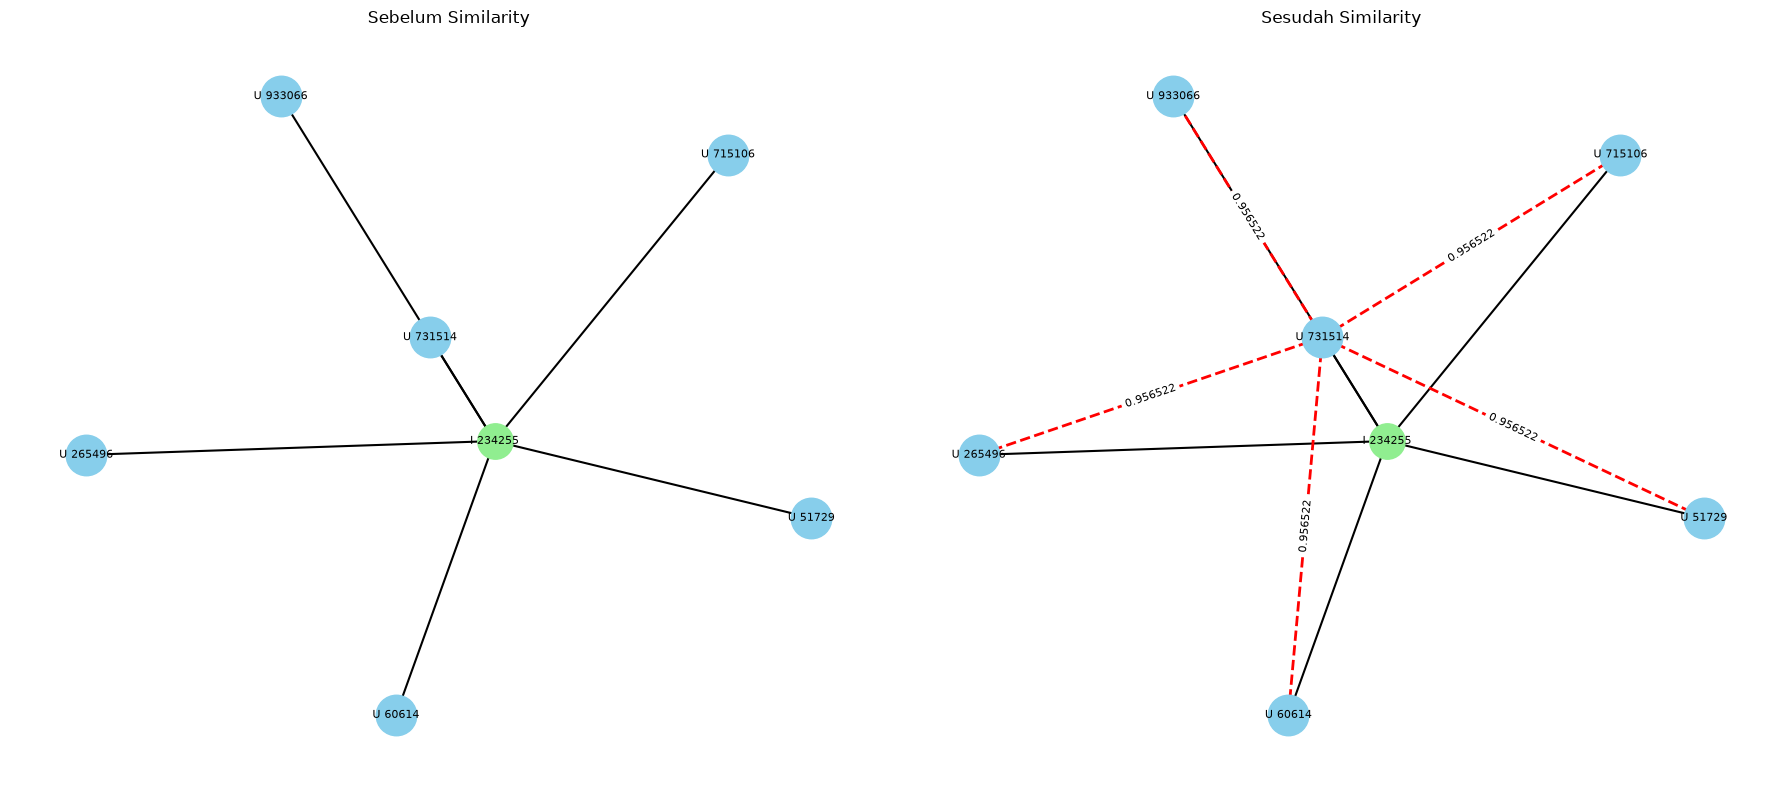

In [135]:
if interactions_df.empty:
    raise ValueError("Data interaksi kosong.")

if similarity_df.empty:
    raise ValueError("Data similarity kosong.")

G_before = nx.Graph()

for uid in [reference_user] + similarity_df["neighbor_id"].astype(int).tolist():
    G_before.add_node(
        ("user", uid),
        label=f"U {uid}",
        kind="user"
    )

for row in interactions_df.itertuples(index=False):
    user_node = ("user", int(row.user_id))
    item_node = ("item", int(row.item_id))

    G_before.add_node(
        user_node,
        label=f"U {int(row.user_id)}",
        kind="user"
    )

    G_before.add_node(
        item_node,
        label=f"I {int(row.item_id)}",
        kind="item"
    )

    G_before.add_edge(
        user_node,
        item_node,
        kind="interaction",
        relation=", ".join(row.event_types)
    )

G_after = G_before.copy()

for row in similarity_df.itertuples(index=False):
    source = ("user", int(row.reference_user))
    neighbor = ("user", int(row.neighbor_id))

    G_after.add_edge(
        source,
        neighbor,
        kind="similarity",
        similarity=float(row.similarity),
        relation=f"{float(row.similarity):.6f}"
    )

pos = nx.spring_layout(G_after, seed=42)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))

for graph, ax, title, show_similarity in [
    (G_before, axes[0], "Sebelum Similarity", False),
    (G_after, axes[1], "Sesudah Similarity", True)
]:
    user_nodes = [
        n for n, d in graph.nodes(data=True)
        if d.get("kind") == "user"
    ]

    item_nodes = [
        n for n, d in graph.nodes(data=True)
        if d.get("kind") == "item"
    ]

    interaction_edges = [
        (u, v) for u, v, d in graph.edges(data=True)
        if d.get("kind") == "interaction"
    ]

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=user_nodes,
        node_color="skyblue",
        node_size=850
    )

    nx.draw_networkx_nodes(
        graph, pos, ax=ax,
        nodelist=item_nodes,
        node_color="lightgreen",
        node_size=650
    )

    nx.draw_networkx_edges(
        graph, pos, ax=ax,
        edgelist=interaction_edges,
        width=1.5
    )

    labels = {
        n: d["label"]
        for n, d in graph.nodes(data=True)
    }

    nx.draw_networkx_labels(
        graph, pos, labels=labels,
        ax=ax, font_size=8
    )

    if show_similarity:
        similarity_edges = [
            (u, v) for u, v, d in graph.edges(data=True)
            if d.get("kind") == "similarity"
        ]

        nx.draw_networkx_edges(
            graph, pos, ax=ax,
            edgelist=similarity_edges,
            edge_color="red",
            style="dashed",
            width=2
        )

        edge_labels = {
            (u, v): d["relation"]
            for u, v, d in graph.edges(data=True)
            if d.get("kind") == "similarity"
        }

        nx.draw_networkx_edge_labels(
            graph, pos,
            edge_labels=edge_labels,
            ax=ax,
            font_size=8
        )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

# Pengerjaan Soal 2.2 Analytics (Maks. skor: 55)

### Menyiapkan KNN untuk Analisis Rekomendasi

Nilai `K` ditetapkan menjadi 5. Lima tetangga teratas diambil dari hasil similarity sebelumnya dan diperiksa jumlah serta keunikannya. Bagian ini memakai User acuan dari langkah pemilihan pada Soal 7.

In [140]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

user_item_df["visitorid"] = (
    user_item_df["visitorid"].astype(int)
)

user_item_df["itemid"] = (
    user_item_df["itemid"].astype(int)
)

user_item_df = (
    user_item_df[["visitorid", "itemid"]]
    .drop_duplicates()
    .reset_index(drop=True)
)

user_ids = sorted(user_item_df["visitorid"].unique())
item_ids = sorted(user_item_df["itemid"].unique())

user_to_idx = {
    int(uid): idx
    for idx, uid in enumerate(user_ids)
}

item_to_idx = {
    int(item_id): idx
    for idx, item_id in enumerate(item_ids)
}

rows = user_item_df["visitorid"].map(user_to_idx).to_numpy()
cols = user_item_df["itemid"].map(item_to_idx).to_numpy()

user_item_matrix = csr_matrix(
    (
        np.ones(len(user_item_df), dtype=np.uint8),
        (rows, cols)
    ),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.uint8
)

X = user_item_matrix.astype(np.int32).tocsr()

A_user_proj = (X @ X.T).tocsr()
A_user_proj.setdiag(0)
A_user_proj.eliminate_zeros()

assert A_user_proj.shape == (len(user_ids), len(user_ids))

print("Jumlah User:", len(user_ids))
print("Shape VSM User-Item:", user_item_matrix.shape)
print("Shape User Projection:", A_user_proj.shape)
print("Pemetaan User berhasil dipulihkan.")

Jumlah User: 34436
Shape VSM User-Item: (34436, 29766)
Shape User Projection: (34436, 34436)
Pemetaan User berhasil dipulihkan.


In [142]:
def get_top_knn_neighbors(user_id, k=5):
    user_idx = user_to_idx[int(user_id)]

    scores = cosine_similarity(
        A_user_proj[user_idx],
        A_user_proj,
        dense_output=True
    ).ravel()

    scores[user_idx] = 0.0

    positive_indices = np.flatnonzero(scores > 0)

    ranked_indices = sorted(
        positive_indices,
        key=lambda idx: (
            -float(scores[idx]),
            int(user_ids[idx])
        )
    )[:k]

    return pd.DataFrame({
        "visitorid": [
            int(user_ids[idx])
            for idx in ranked_indices
        ],
        "similarity": [
            float(scores[idx])
            for idx in ranked_indices
        ]
    })


eligible_analytics_users = []
neighbors_by_user = {}

for uid in base_candidates:
    neighbors = get_top_knn_neighbors(uid, k=K)

    if len(neighbors) != K:
        continue

    neighbor_item_candidates = set()

    for neighbor_id in neighbors["visitorid"]:
        neighbor_item_candidates.update(
            user_item_history.get(int(neighbor_id), set())
        )

    new_items = (
        neighbor_item_candidates
        - user_item_history.get(uid, set())
    )

    if len(new_items) >= 3:
        eligible_analytics_users.append(uid)
        neighbors_by_user[uid] = neighbors

eligible_analytics_users = sorted(
    eligible_analytics_users
)

if not eligible_analytics_users:
    raise ValueError(
        "Tidak ditemukan User yang memenuhi seluruh "
        "kriteria rekomendasi KNN."
    )

print(
    "Jumlah User yang memenuhi syarat:",
    len(eligible_analytics_users)
)

Jumlah User yang memenuhi syarat: 387


In [143]:
rng = np.random.default_rng(SEED_ANALYTICS)

analytics_user = int(
    rng.choice(eligible_analytics_users)
)

analytics_neighbors = neighbors_by_user[analytics_user]

target_history = user_item_history.get(
    analytics_user, set()
)

neighbor_ids = set(
    analytics_neighbors["visitorid"].astype(int)
)

print("Random seed:", SEED_ANALYTICS)
print("User Analytics terpilih:", analytics_user)
print("Jumlah tetangga KNN:", len(analytics_neighbors))

print("\nLima tetangga KNN:")
display(analytics_neighbors)

Random seed: 42
User Analytics terpilih: 139754
Jumlah tetangga KNN: 5

Lima tetangga KNN:


,visitorid,similarity
0,1059287,0.666667
1,1195136,0.666667
2,860540,0.577350
3,483207,0.408248
4,1248805,0.308607


### Menghitung Rekomendasi KNN dari User Acuan Sebelumnya

Cell ini membuat skor rekomendasi berdasarkan riwayat interaksi P1 dari lima tetangga yang sudah dipilih. Item yang telah ada pada riwayat User acuan dihapus, lalu item yang tersisa diurutkan berdasarkan skor rekomendasi. Bagian ini merupakan proses rekomendasi untuk User acuan dari langkah sebelumnya; hasil khusus Analytics dihitung kembali setelah User Analytics dipilih pada cell berikutnya.

In [144]:
neighbor_item_pairs = (
    train_interactions.loc[
        train_interactions["visitorid"].isin(neighbor_ids),
        ["visitorid", "itemid"]
    ]
    .drop_duplicates()
)

neighbor_item_scores = neighbor_item_pairs.merge(
    analytics_neighbors[["visitorid", "similarity"]],
    on="visitorid",
    how="inner"
)

recommendation_scores = (
    neighbor_item_scores
    .groupby("itemid")
    .agg(
        recommendation_score=("similarity", "sum"),
        supporting_neighbors=("visitorid", "nunique")
    )
    .reset_index()
)

recommendation_scores = recommendation_scores.loc[
    ~recommendation_scores["itemid"].isin(target_history)
].copy()

recommendation_scores = recommendation_scores.sort_values(
    [
        "recommendation_score",
        "supporting_neighbors",
        "itemid"
    ],
    ascending=[False, False, True]
).reset_index(drop=True)

if len(recommendation_scores) < 3:
    raise ValueError(
        "Kandidat item baru kurang dari tiga."
    )

print(
    "Jumlah kandidat item setelah filtering:",
    len(recommendation_scores)
)

print("\nLima rekomendasi teratas:")
display(recommendation_scores.head(5))

Jumlah kandidat item setelah filtering: 28

Lima rekomendasi teratas:


,itemid,recommendation_score,supporting_neighbors
0,37773,0.885957,2
1,217078,0.716855,2
2,313852,0.666667,1
3,9088,0.308607,1
4,17944,0.308607,1


In [145]:
top3_recommendations = recommendation_scores.head(3).copy()

top3_recommendations.insert(
    0,
    "rank",
    range(1, len(top3_recommendations) + 1)
)

top3_recommendations = top3_recommendations.rename(
    columns={
        "itemid": "item_rekomendasi",
        "recommendation_score": "skor_rekomendasi",
        "supporting_neighbors": "jumlah_tetangga_pendukung"
    }
)

print("User Analytics terpilih:", analytics_user)
print("\nTiga item rekomendasi:")
display(top3_recommendations)

User Analytics terpilih: 139754

Tiga item rekomendasi:


,rank,item_rekomendasi,skor_rekomendasi,jumlah_tetangga_pendukung
0,1,37773,0.885957,2
1,2,217078,0.716855,2
2,3,313852,0.666667,1


### Metode: Menyiapkan Top-5 dan Ground Truth

Lima rekomendasi teratas diambil untuk evaluasi. Data P2 untuk User target dibandingkan dengan riwayat P1, lalu item P2 yang belum ada pada riwayat P1 ditetapkan sebagai ground truth atau item relevan. Definisi relevansi ini digunakan untuk menguji rekomendasi item baru.

In [146]:
evaluation_user = int(analytics_user)

top5_recommendations = recommendation_scores.head(5).copy()

top5_recommendations.insert(
    0,
    "rank",
    range(1, len(top5_recommendations) + 1)
)

test_items = set(
    test_df.loc[
        test_df["visitorid"].astype(int) == evaluation_user,
        "itemid"
    ].astype(int).unique()
)

training_history = set(
    train_df.loc[
        train_df["visitorid"].astype(int) == evaluation_user,
        "itemid"
    ].astype(int).unique()
)

ground_truth_items = test_items - training_history

print("User yang dievaluasi:", evaluation_user)
print("Jumlah item unik pada P2:", len(test_items))
print("Jumlah item dalam riwayat P1:", len(training_history))
print("Jumlah item relevan:", len(ground_truth_items))
print("Ground truth:", sorted(ground_truth_items))

print("\nLima rekomendasi teratas:")
display(top5_recommendations)

User yang dievaluasi: 139754
Jumlah item unik pada P2: 1
Jumlah item dalam riwayat P1: 1
Jumlah item relevan: 1
Ground truth: [np.int64(369901)]

Lima rekomendasi teratas:


,rank,itemid,recommendation_score,supporting_neighbors
0,1,37773,0.885957,2
1,2,217078,0.716855,2
2,3,313852,0.666667,1
3,4,9088,0.308607,1
4,5,17944,0.308607,1


### Metode: Menghitung Hit@5 dan NDCG@5

Label relevansi bernilai 1 jika item rekomendasi ada di ground truth, dan 0 jika tidak. Hit@5 memeriksa apakah setidaknya satu dari lima rekomendasi relevan. NDCG@5 membandingkan nilai DCG dari urutan rekomendasi dengan urutan ideal, sehingga posisi item relevan ikut diperhitungkan.

In [147]:
if not ground_truth_items:
    raise ValueError(
        "Ground truth kosong. User ini tidak memiliki item baru "
        "pada P2 yang dapat digunakan untuk evaluasi."
    )

recommended_items = (
    top5_recommendations["itemid"].astype(int).tolist()
)

relevance = [
    1 if item_id in ground_truth_items else 0
    for item_id in recommended_items
]

hit_at_5 = int(any(relevance))

dcg_at_5 = sum(
    rel / np.log2(rank + 1)
    for rank, rel in enumerate(relevance, start=1)
)

ideal_hits = min(5, len(ground_truth_items))

idcg_at_5 = sum(
    1 / np.log2(rank + 1)
    for rank in range(1, ideal_hits + 1)
)

ndcg_at_5 = (
    dcg_at_5 / idcg_at_5
    if idcg_at_5 > 0
    else 0.0
)

evaluation_df = top5_recommendations[
    ["rank", "itemid"]
].copy()

evaluation_df["relevance"] = relevance

print("Evaluasi rekomendasi User:", evaluation_user)
display(evaluation_df)

print(f"Hit@5  : {hit_at_5}")
print(f"DCG@5  : {dcg_at_5:.6f}")
print(f"IDCG@5 : {idcg_at_5:.6f}")
print(f"NDCG@5 : {ndcg_at_5:.6f}")

Evaluasi rekomendasi User: 139754


,rank,itemid,relevance
0,1,37773,0
1,2,217078,0
2,3,313852,0
3,4,9088,0
4,5,17944,0


Hit@5  : 0
DCG@5  : 0.000000
IDCG@5 : 1.000000
NDCG@5 : 0.000000
